# **Uploading the dataset**

In [1]:
import pandas as pd

In [2]:
data = pd.read_csv("combined_emails_classes.csv",encoding = "latin1") # this dataset is latin1 encoding based

In [3]:
data.head()

,email_subject,email_body,email_category,urgency level,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,Account Access Issue - Invalid Credentials,I'm unable to access my {product_purchased} ac...,inquiry,medium,NaN,NaN,NaN,NaN,NaN,NaN
1,Help Needed - Action Option Missing,m having an issue with the {product_purchased}...,inquiry,medium,NaN,NaN,NaN,NaN,NaN,NaN
2,Issue Reported - Product Assistance,I'm having an issue with the {product_purchase...,inquiry,medium,NaN,NaN,NaN,NaN,NaN,NaN
3,Troubleshooting Steps Didn't Resolve Problem,I'm having an issue with the {product_purchase...,inquiry,medium,NaN,NaN,NaN,NaN,NaN,NaN
4,Concern: Product Security & Data Safety,I'm having an issue with the {product_purchase...,inquiry,medium,NaN,NaN,NaN,NaN,NaN,NaN


# **Exploratory Data Analysis**

In [4]:
data.shape

(704, 10)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 704 entries, 0 to 703
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   email_subject   572 non-null    object 
 1   email_body      572 non-null    object 
 2   email_category  572 non-null    object 
 3   urgency level   572 non-null    object 
 4   Unnamed: 4      0 non-null      float64
 5   Unnamed: 5      2 non-null      float64
 6   Unnamed: 6      1 non-null      float64
 7   Unnamed: 7      0 non-null      float64
 8   Unnamed: 8      0 non-null      float64
 9   Unnamed: 9      1 non-null      float64
dtypes: float64(6), object(4)
memory usage: 55.1+ KB


In [6]:
data.describe()

,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
count,0.0,2.000000,1.0,0.0,0.0,1.0
mean,NaN,394.000000,725.0,NaN,NaN,633.0
std,NaN,354.967604,NaN,NaN,NaN,NaN
min,NaN,143.000000,725.0,NaN,NaN,633.0
25%,NaN,268.500000,725.0,NaN,NaN,633.0
50%,NaN,394.000000,725.0,NaN,NaN,633.0
75%,NaN,519.500000,725.0,NaN,NaN,633.0
max,NaN,645.000000,725.0,NaN,NaN,633.0


In [7]:
data.isnull().sum() # looking for total nan values in all rows

,0
email_subject,132
email_body,132
email_category,132
urgency level,132
Unnamed: 4,704
Unnamed: 5,702
Unnamed: 6,703
Unnamed: 7,704
Unnamed: 8,704
Unnamed: 9,703


# **Data Cleaning Process**

### Drop the unwanted columns

In [8]:
data.drop(columns=["Unnamed: 4","Unnamed: 5", "Unnamed: 6", "Unnamed: 7", "Unnamed: 8", "Unnamed: 9"], inplace=True)

## Drop all the NaN values in all rows

In [9]:
data = data.dropna()

In [10]:
data.head()

,email_subject,email_body,email_category,urgency level
0,Account Access Issue - Invalid Credentials,I'm unable to access my {product_purchased} ac...,inquiry,medium
1,Help Needed - Action Option Missing,m having an issue with the {product_purchased}...,inquiry,medium
2,Issue Reported - Product Assistance,I'm having an issue with the {product_purchase...,inquiry,medium
3,Troubleshooting Steps Didn't Resolve Problem,I'm having an issue with the {product_purchase...,inquiry,medium
4,Concern: Product Security & Data Safety,I'm having an issue with the {product_purchase...,inquiry,medium


In [11]:
data.shape

(572, 4)

In [12]:
data.describe()

,email_subject,email_body,email_category,urgency level
count,572,572,572,572
unique,367,548,4,3
top,Payments & Transactions,Congratulations ur awarded 500 of CD vouchers ...,spam,medium
freq,43,3,151,270


In [13]:
print(data["email_category"].unique())
print(data['email_category'].value_counts())

['inquiry' 'spam' 'feedback' 'complaint']
email_category
spam         151
complaint    151
inquiry      144
feedback     126
Name: count, dtype: int64


In [14]:
print(data["urgency level"].unique())
print(data['urgency level'].value_counts())

['medium' 'low' 'high']
urgency level
medium    270
low       151
high      151
Name: count, dtype: int64


In [15]:
data.isnull().sum() # checking the null value after the removal

,0
email_subject,0
email_body,0
email_category,0
urgency level,0


# Data Preprocessing

In [16]:
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


In [17]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [18]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

In [19]:
def clean_email(text):
    # Lowercase
    text = text.lower()
    # Remove email IDs
    text = re.sub(r'\S+@\S+', "", text)
    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)
    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))
    # Tokenize
    words = text.split()
    # Remove stopwords + lemmatize
    processed_words = [lemmatizer.lemmatize(w) for w in words if w not in stop_words]
    return " ".join(processed_words)


In [20]:
cleaned_subjects = [clean_email(e) for e in data["email_subject"]]
data["email_subject"] = cleaned_subjects

In [21]:
cleaned_body = [clean_email(e) for e in data['email_body']]
data['email_body'] = cleaned_body

In [22]:
data.head()

,email_subject,email_body,email_category,urgency level
0,account access issue invalid credential,im unable access productpurchased account keep...,inquiry,medium
1,help needed action option missing,issue productpurchased please assist possible ...,inquiry,medium
2,issue reported product assistance,im issue productpurchased please assist acknow...,inquiry,medium
3,troubleshooting step didnt resolve problem,im issue productpurchased please assist thanks...,inquiry,medium
4,concern product security data safety,im issue productpurchased please assist want a...,inquiry,medium


## Encoding the email category and urgency level

In [23]:
from sklearn.preprocessing import LabelEncoder

# For email_category
le_category = LabelEncoder()
data['email_category'] = le_category.fit_transform(data['email_category'])

print("Email Category Mapping:")
for i, label in enumerate(le_category.classes_):
    print(f"{label} --> {i}")

# For urgency level
le_urgency = LabelEncoder()
data['urgency level'] = le_urgency.fit_transform(data['urgency level'])

print("\nUrgency Level Mapping:")
for i, label in enumerate(le_urgency.classes_):
    print(f"{label} --> {i}")

Email Category Mapping:
complaint --> 0
feedback --> 1
inquiry --> 2
spam --> 3

Urgency Level Mapping:
high --> 0
low --> 1
medium --> 2


In [24]:
data.head()

,email_subject,email_body,email_category,urgency level
0,account access issue invalid credential,im unable access productpurchased account keep...,2,2
1,help needed action option missing,issue productpurchased please assist possible ...,2,2
2,issue reported product assistance,im issue productpurchased please assist acknow...,2,2
3,troubleshooting step didnt resolve problem,im issue productpurchased please assist thanks...,2,2
4,concern product security data safety,im issue productpurchased please assist want a...,2,2


In [25]:
data.to_excel("cleaned_email_dataset.xlsx", index = False) # downloading the cleaned email data as an excel file

## Splitting into input features and target

In [28]:
X = data.iloc[:,:2] # input features

y1 = data.iloc[:,2] # first target - classification
y2 = data.iloc[:,3] # second target - urgency level

In [29]:
X

,email_subject,email_body
0,account access issue invalid credential,im unable access productpurchased account keep...
1,help needed action option missing,issue productpurchased please assist possible ...
2,issue reported product assistance,im issue productpurchased please assist acknow...
3,troubleshooting step didnt resolve problem,im issue productpurchased please assist thanks...
4,concern product security data safety,im issue productpurchased please assist want a...
...,...,...
567,telecom isp service,comcast imposed new usage cap 300gb punishes s...
568,telecom isp service,comcast working service boot
569,telecom isp service,isp charging arbitrary data limit overage fee
570,telecom isp service,throttling service unreasonable data cap


In [30]:
y1

,email_category
0,2
1,2
2,2
3,2
4,2
...,...
567,0
568,0
569,0
570,0


## Using TF-ID Vectorizer

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer

# combine two features into one string per row
combined_text = data['email_subject'].fillna("") + " " + data['email_subject'].fillna("")

# single string row will be given as as input to TfidVectorizer
vectorizer = TfidfVectorizer(max_features  = 5000,
                             min_df = 7,
                             max_df = 0.2,
                             ngram_range = (1,2))

X = vectorizer.fit_transform(combined_text).toarray()


In [32]:
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

# Splitting into training and testing for classification feature

In [33]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X, y1, test_size = 0.2, random_state = 42) # for classifying the email categories

# Logistic Regression

A common issue in machine learning is receiving a ConvergenceWarning, which means the model stopped training because it hit the max_iter limit before finding the optimal solution. In such cases, increasing the number of iterations can resolve the warning and potentially improve the model's performance

In [34]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter = 1000)
lr.fit(X_train,y_train)

LogisticRegression(max_iter=1000)

In [35]:
y1_pred = lr.predict(X_test)
y1_pred

array([0, 2, 2, 3, 0, 1, 3, 2, 2, 1, 0, 3, 0, 0, 0, 2, 1, 3, 2, 3, 2, 3,
       1, 3, 0, 2, 3, 1, 3, 2, 3, 3, 0, 3, 3, 2, 2, 3, 2, 2, 2, 0, 1, 3,
       3, 2, 3, 0, 3, 0, 1, 2, 3, 3, 3, 1, 3, 2, 2, 3, 2, 2, 3, 3, 3, 0,
       2, 2, 3, 3, 1, 2, 1, 0, 1, 0, 3, 1, 3, 3, 2, 3, 2, 1, 3, 0, 2, 0,
       3, 0, 2, 3, 1, 0, 1, 2, 3, 3, 3, 3, 0, 2, 2, 1, 0, 1, 0, 3, 0, 3,
       2, 3, 0, 0, 2])

In [36]:
from sklearn.metrics import accuracy_score,classification_report

accuracy = accuracy_score(y_test,y1_pred)
print("Accuracy:",(accuracy)*100)

Accuracy: 90.43478260869566


In [37]:
report = classification_report(y_test,y1_pred)
print("Report:",report)

Report:               precision    recall  f1-score   support

           0       1.00      0.80      0.89        30
           1       0.88      0.79      0.83        19
           2       1.00      1.00      1.00        32
           3       0.79      0.97      0.87        34

    accuracy                           0.90       115
   macro avg       0.92      0.89      0.90       115
weighted avg       0.92      0.90      0.90       115



# Multinomial Naive Bayes

In [38]:
from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB()
nb.fit(X_train,y_train)

MultinomialNB()

In [39]:
y1_pred2 = nb.predict(X_test)
y1_pred2

array([0, 2, 2, 0, 0, 1, 0, 2, 2, 1, 0, 0, 0, 0, 0, 2, 1, 0, 2, 0, 2, 3,
       1, 0, 0, 2, 3, 1, 3, 2, 0, 3, 0, 0, 3, 2, 2, 0, 2, 2, 2, 0, 1, 3,
       3, 2, 3, 0, 3, 0, 1, 2, 3, 3, 0, 1, 0, 2, 2, 0, 2, 2, 3, 0, 3, 0,
       2, 2, 0, 3, 1, 2, 1, 0, 1, 0, 0, 1, 0, 0, 2, 3, 2, 1, 3, 0, 2, 0,
       3, 0, 2, 3, 1, 0, 1, 2, 3, 3, 3, 3, 0, 2, 2, 1, 0, 1, 0, 0, 0, 3,
       2, 3, 0, 0, 2])

In [40]:
accuracy = accuracy_score(y_test,y1_pred2)
print("Accuracy:",round(accuracy,2)*100)

Accuracy: 82.0


In [41]:
report = classification_report(y_test,y1_pred2)
print("Report:",report)

Report:               precision    recall  f1-score   support

           0       0.62      0.87      0.72        30
           1       0.88      0.79      0.83        19
           2       1.00      1.00      1.00        32
           3       0.88      0.62      0.72        34

    accuracy                           0.82       115
   macro avg       0.84      0.82      0.82       115
weighted avg       0.84      0.82      0.82       115



# Fine tuning using Transformer models

## Using DistilBERT Model


In [42]:
import torch
from transformers import DistilBertTokenizerFast,DistilBertForSequenceClassification

## converting combined texts and labels into list for BERT abd DistilBERT tokenization


In [43]:
email_list = combined_text.tolist()
category_list = y1.tolist()

In [44]:
email_list[1:5]

['help needed action option missing help needed action option missing',
 'issue reported product assistance issue reported product assistance',
 'troubleshooting step didnt resolve problem troubleshooting step didnt resolve problem',
 'concern product security data safety concern product security data safety']

## Tokenizer

In [45]:

tokenizer = DistilBertTokenizerFast.from_pretrained(
    "distilbert-base-uncased"
)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

## Define the Torch Dataset

When you fine‑tune a transformer model (like DistilBERT), the Trainer or a PyTorch DataLoader expects the data in a very specific format:
- Inputs: tokenized tensors (input_ids, attention_mask, etc.)
- Labels: numeric class IDs (0, 1, 2, 3 for your categories)


Your raw data (texts, labels) is just Python lists. The tokenizer gives you NumPy arrays or lists of IDs. But the model needs PyTorch tensors wrapped in a dataset object that can be indexed and iterated.


In [46]:
class EmailDataset(torch.utils.data.Dataset):
  def __init__(self, encodings, labels): # stores the encodings (tokenized emails) and category labels
    self.encodings = encodings
    self.labels = labels

  def __getitem__(self,idx): # when you ask for dataset[5], it returns a dictionary like
    item = {key: torch.tensor(val[idx]) for key,val in self.encodings.items()}
    item['labels'] = torch.tensor(self.labels[idx])
    return item

  def __len__(self): # tells Pytorch how many samples are in the dataset
    return len(self.labels)

## Splitting into training and testing


In [47]:
train_texts, test_texts, train_labels, test_labels = train_test_split(
    email_list, category_list, test_size = 0.2, random_state = 42
)

In [48]:
# tokenize the train and test emails

train_encodings = tokenizer(
    train_texts,
    truncation=True, # cut the long emails
    padding=True, # equal length for batching
    max_length=128)

test_encodings = tokenizer(
    test_texts,
    truncation=True,
    padding=True,
    max_length=128)


In [49]:
# Make them as Pytorch Dataset

train_dataset = EmailDataset(train_encodings, train_labels)
test_dataset = EmailDataset(test_encodings, test_labels)


In [50]:
# Load the DistilBERT model

model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels = 4 # 4 email category
)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## Model Training

In [53]:

from transformers import Trainer,TrainingArguments

training_args = TrainingArguments(
    output_dir = "./results",
    num_train_epochs = 3, # finetuning
    per_device_train_batch_size = 8, # safe for limited GPU
    logging_steps = 10,
    save_strategy = "no" # avoids the saving checkpoints for the demo
)

In [54]:
trainer1 = Trainer(
    model = model,
    args = training_args,
    train_dataset = train_dataset,
    eval_dataset = test_dataset,
)

trainer1.train()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
10,1.309181
20,0.918863
30,0.743380
40,0.396049
50,0.254715
60,0.136562
70,0.108114
80,0.077532
90,0.038485
100,0.083529


TrainOutput(global_step=174, training_loss=0.2470486209481612, metrics={'train_runtime': 165.8588, 'train_samples_per_second': 8.266, 'train_steps_per_second': 1.049, 'total_flos': 10641754756080.0, 'train_loss': 0.2470486209481612, 'epoch': 3.0})

## Evaluation

In [57]:
predictions = trainer1.predict(test_dataset)
y_pred = predictions.predictions.argmax(axis=1)
y_true = predictions.label_ids


In [58]:
acc = accuracy_score(y_true, y_pred)
print("Accuracy:", acc*100)

report = classification_report(y_true,y_pred)
print("Classification report:", report)

Accuracy: 97.3913043478261
Classification report:               precision    recall  f1-score   support

           0       1.00      0.93      0.97        30
           1       0.90      1.00      0.95        19
           2       1.00      1.00      1.00        32
           3       0.97      0.97      0.97        34

    accuracy                           0.97       115
   macro avg       0.97      0.98      0.97       115
weighted avg       0.98      0.97      0.97       115



## Using BERT model

In [59]:
from transformers import BertTokenizerFast, BertForSequenceClassification

train_texts, test_texts, train_labels, test_labels = train_test_split(
    email_list, category_list, test_size=0.2, random_state=42
)


### Tokenizer

In [60]:
# Tokenizer
tokenizer = BertTokenizerFast.from_pretrained("bert-base-uncased")

train_encodings = tokenizer(train_texts, truncation=True, padding=True, max_length=128)
test_encodings = tokenizer(test_texts, truncation=True, padding=True, max_length=128)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [61]:
# ---------------- Dataset Class ----------------
class EmailDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = EmailDataset(train_encodings, train_labels)
test_dataset = EmailDataset(test_encodings, test_labels)


In [62]:
model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=4  # compliant, request, spam, feedback
)


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [64]:
training_args1 = TrainingArguments(
    output_dir="./results",
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    logging_steps=10,
    save_strategy="no"
)


In [65]:
trainer2 = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
)
trainer2.train()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
10,1.173485
20,0.720221
30,0.658482
40,0.401049
50,0.320531
60,0.151668
70,0.141402
80,0.059569
90,0.066728
100,0.077877


TrainOutput(global_step=174, training_loss=0.22737283546520376, metrics={'train_runtime': 315.8156, 'train_samples_per_second': 4.341, 'train_steps_per_second': 0.551, 'total_flos': 21136625069040.0, 'train_loss': 0.22737283546520376, 'epoch': 3.0})

In [66]:
predictions = trainer2.predict(test_dataset)
y_pred = predictions.predictions.argmax(axis=1)
y_true = predictions.label_ids

print("Accuracy:", accuracy_score(y_true, y_pred)*100)
print("Classification Report:",classification_report(y_true, y_pred))


Accuracy: 95.65217391304348
Classification Report:               precision    recall  f1-score   support

           0       1.00      0.93      0.97        30
           1       0.90      1.00      0.95        19
           2       1.00      0.94      0.97        32
           3       0.92      0.97      0.94        34

    accuracy                           0.96       115
   macro avg       0.96      0.96      0.96       115
weighted avg       0.96      0.96      0.96       115



# Saving the best model for the classification for local deployment


DistilBERT model has the highest accuracy

In [67]:
# Save the trained model
trainer1.model.save_pretrained("saved_model")

# Save the tokenizer (must be the same one you used for training)
tokenizer.save_pretrained("saved_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('saved_model/tokenizer_config.json', 'saved_model/tokenizer.json')

# **Urgency Prediction**

In [68]:
urgency_labels = [
    "high",
    "medium",
    "low",
]

In [69]:
y2.unique()

array([2, 1, 0])

In [ ]:
y_urgency = [urgency_map[u] for u in urgency_labels]
y_urgency

## Rule Based Urgency Keywords definition

In [70]:
high_urgency_word = [
    "urgent",
    "asap",
    "immediately",
    "not work",
    "down",
    "fail",

]

In [71]:
medium_urgency_words = [
    "soon",
    "please",
    "request",
    "help",
    "issue"
]

In [72]:
# defining rule-based urgency function

def rule_based_urgency(text):
  text = text.lower()

  for word in high_urgency_word:
    if word in text:
      return "high"

  for word in medium_urgency_words:
    if word in text:
      return "medium"

  return "low"

In [73]:
from sklearn.model_selection import train_test_split

X_train1,X_test1,y_train1,y_test1 = train_test_split(
    X,y2, test_size = 0.2, random_state = 42)

## ML Prediction

### Logistic Regression

In [74]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train1,y_train1)

LogisticRegression(max_iter=1000)

In [75]:
y2_pred = lr.predict(X_test1)
y2_pred

array([0, 2, 2, 2, 0, 2, 2, 2, 2, 2, 0, 2, 0, 0, 0, 2, 2, 2, 2, 2, 2, 1,
       2, 2, 0, 2, 1, 2, 1, 2, 2, 1, 0, 2, 1, 2, 2, 2, 2, 2, 2, 0, 2, 1,
       1, 2, 1, 0, 1, 0, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 0,
       2, 2, 1, 1, 2, 2, 2, 0, 2, 0, 2, 2, 2, 2, 2, 1, 2, 2, 1, 0, 2, 0,
       1, 0, 2, 1, 2, 0, 2, 2, 1, 1, 1, 1, 0, 2, 2, 2, 0, 2, 0, 2, 0, 1,
       2, 1, 0, 0, 2])

In [76]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# F1-score for multiclass
print("F1-score (weighted):", f1_score(y_test1, y2_pred, average='weighted'))


F1-score (weighted): 0.8389924985356083


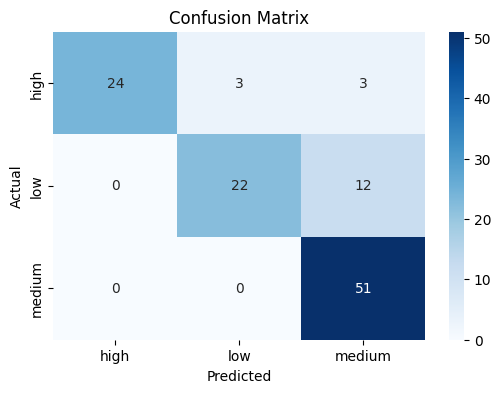

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm = confusion_matrix(y_test1, y2_pred)
labels = ['high', 'low', 'medium'] # adjusted based on the label encoded

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### Naive Bayes

In [78]:
from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB()
nb.fit(X_train1,y_train1)

MultinomialNB()

In [79]:
y2_pred2 = nb.predict(X_test1)
y2_pred2

array([0, 2, 2, 2, 0, 2, 2, 2, 2, 2, 0, 2, 0, 0, 2, 2, 2, 2, 2, 2, 2, 1,
       2, 2, 0, 2, 1, 2, 1, 2, 2, 2, 0, 2, 1, 2, 2, 2, 2, 2, 2, 0, 2, 1,
       1, 2, 2, 0, 2, 0, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0,
       2, 2, 0, 1, 2, 2, 2, 0, 2, 0, 2, 2, 2, 2, 2, 1, 2, 2, 1, 0, 2, 0,
       1, 0, 2, 1, 2, 0, 2, 2, 2, 1, 1, 1, 0, 2, 2, 2, 0, 2, 0, 2, 0, 1,
       2, 1, 0, 0, 2])

In [80]:
print("F1-score", f1_score(y_test1,y2_pred2,average = "weighted"))

F1-score 0.7917011304108078


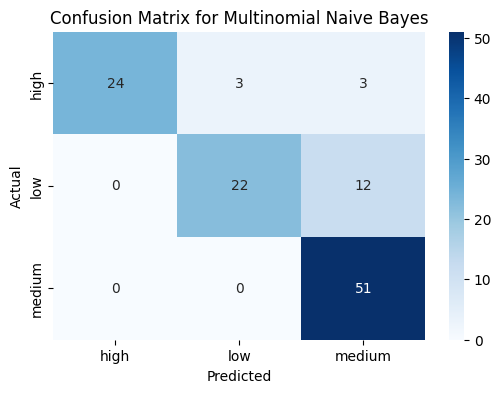

In [81]:
cm2 = confusion_matrix(y_test1,y2_pred2)
plt.figure(figsize=(6,4))
sns.heatmap(cm,annot = True, fmt = "d",cmap = "Blues",
            xticklabels = labels, yticklabels = labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Multinomial Naive Bayes")
plt.show()


In [82]:
print("Accuracy:",accuracy_score(y_test1,y2_pred2))

Accuracy: 0.8


### DistilBERT

In [83]:
import torch
from transformers import DistilBertTokenizerFast,DistilBertForSequenceClassification

# converting combined texts and labels into list for BERT abd DistilBERT tokenization


email_list2 = combined_text.tolist()
urgency_list = y2.tolist()

In [85]:
tokenizer = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

In [86]:

class EmailDataset(torch.utils.data.Dataset):
  def __init__(self, encodings, labels): # stores the encodings (tokenized emails) and category labels
    self.encodings = encodings
    self.labels = labels

  def __getitem__(self,idx): # when you ask for dataset[5], it returns a dictionary like
    item = {key: torch.tensor(val[idx]) for key,val in self.encodings.items()}
    item['labels'] = torch.tensor(self.labels[idx])
    return item

  def __len__(self): # tells Pytorch how many samples are in the dataset
    return len(self.labels)



In [87]:
train_texts, test_texts, train_labels, test_labels = train_test_split(email_list2, urgency_list, test_size = 0.2, random_state = 42)

In [88]:
train_encodings = tokenizer(
    train_texts,
    truncation = True,
    padding = True,
    max_length = 128
)

test_encodings = tokenizer(
    test_texts,
    truncation = True,
    padding = True,
    max_length = 128
)

In [89]:
# Make them as Pytorch Dataset

train_dataset = EmailDataset(train_encodings, train_labels)
test_dataset = EmailDataset(test_encodings, test_labels)

In [90]:

model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels = 4 # 4 email category
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [92]:
from transformers import Trainer,TrainingArguments

training_args = TrainingArguments(
    output_dir = "./results",
    num_train_epochs = 3, # finetuning
    per_device_train_batch_size = 8, # safe for limited GPU
    logging_steps = 10,
    save_strategy = "no" # avoids the saving checkpoints for the demo
)



In [93]:
trainer1 = Trainer(
    model = model,
    args = training_args,
    train_dataset = train_dataset,
    eval_dataset = test_dataset,
)

trainer1.train()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
10,1.204168
20,0.753089
30,0.549528
40,0.259292
50,0.221007
60,0.088209
70,0.047270
80,0.050929
90,0.061661
100,0.037076


TrainOutput(global_step=174, training_loss=0.19151087329005714, metrics={'train_runtime': 161.4653, 'train_samples_per_second': 8.491, 'train_steps_per_second': 1.078, 'total_flos': 10641754756080.0, 'train_loss': 0.19151087329005714, 'epoch': 3.0})

In [94]:
predictions = trainer1.predict(test_dataset)
y2_pred3 = predictions.predictions.argmax(axis=1)
y2_true = predictions.label_ids

In [95]:

# F1-score (multiclass → use average)
print("F1-score (weighted):", f1_score(test_labels , y2_pred3, average='weighted'))


F1-score (weighted): 0.9563549321745121


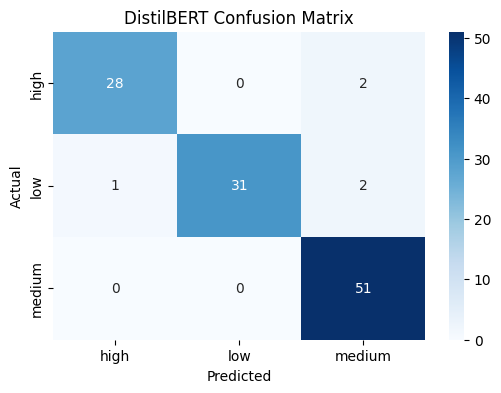

In [96]:
cm = confusion_matrix(test_labels, y2_pred3)

labels = ['high', 'low', 'medium']
cm_df = pd.DataFrame(cm, index=labels, columns=labels)


plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('DistilBERT Confusion Matrix')
plt.show()


### Saving the BERT model

In [97]:

# Save the trained model
trainer1.model.save_pretrained("saved_model")

# Save the tokenizer (must be the same one you used for training)
tokenizer.save_pretrained("saved_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('saved_model/tokenizer_config.json', 'saved_model/tokenizer.json')